#  Face Matching Analysis: Kids vs Adults


**What this notebook does, for EACH category separately:**
1. MTCNN detection + alignment
2. 4 versions: `original`, `gaussian_noise`, `salt_pepper_noise`, `synthetic_resize`
3. FaceNet embeddings
4. Genuine scores (same subject) and impostor scores (different subjects **+ UTKFace
   distractors**) via cosine similarity
5. Score distributions, ROC/EER, and **score vs. age-gap** trend



In [1]:
import os
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm
from facenet_pytorch import MTCNN, InceptionResnetV1
from sklearn.metrics import roc_curve, auc

sns.set_style("whitegrid")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

DATASET_ROOT = "./dataset_v2"
CATEGORIES = ["kids", "adults"]


Using device: cpu


## 1. Models + perturbation functions

In [2]:
mtcnn = MTCNN(image_size=160, margin=20, keep_all=False, post_process=True, device=device)
facenet = InceptionResnetV1(pretrained="vggface2").eval().to(device)

def detect_and_align(pil_img):
    return mtcnn(pil_img)

def embed(face_tensor):
    with torch.no_grad():
        e = facenet(face_tensor.unsqueeze(0).to(device))
    return e.squeeze(0).cpu().numpy()

def add_gaussian_noise(img_bgr, mean=0, sigma=25):
    noise = np.random.normal(mean, sigma, img_bgr.shape).astype(np.float32)
    noisy = img_bgr.astype(np.float32) + noise
    return np.clip(noisy, 0, 255).astype(np.uint8)

def add_salt_pepper_noise(img_bgr, amount=0.02, salt_vs_pepper=0.5):
    out = img_bgr.copy()
    num_salt = int(np.ceil(amount * img_bgr.size * salt_vs_pepper))
    num_pepper = int(np.ceil(amount * img_bgr.size * (1.0 - salt_vs_pepper)))
    coords = [np.random.randint(0, i, num_salt) for i in img_bgr.shape[:2]]
    out[coords[0], coords[1], :] = 255
    coords = [np.random.randint(0, i, num_pepper) for i in img_bgr.shape[:2]]
    out[coords[0], coords[1], :] = 0
    return out

def synthetic_resize(img_bgr, scale=0.25):
    h, w = img_bgr.shape[:2]
    small = cv2.resize(img_bgr, (max(1, int(w * scale)), max(1, int(h * scale))),
                        interpolation=cv2.INTER_LINEAR)
    return cv2.resize(small, (w, h), interpolation=cv2.INTER_CUBIC)

VERSIONS = {
    "original":          lambda img: img,
    "gaussian_noise":    lambda img: add_gaussian_noise(img, mean=0, sigma=25),
    "salt_pepper_noise": lambda img: add_salt_pepper_noise(img, amount=0.02),
    "synthetic_resize":  lambda img: synthetic_resize(img, scale=0.25),
}

def cosine_sim(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))


## 2. Reusable pipeline function

Runs the full embedding + genuine/impostor + EER + score-vs-age-gap pipeline for a single
category folder, using that category's own `distractors/` folder to enrich the impostor pool.


In [3]:
def run_pipeline(category_name):
    cat_dir = os.path.join(DATASET_ROOT, category_name)
    meta = pd.read_csv(os.path.join(cat_dir, "metadata.csv"), dtype={"subject_id": str})
    distractor_dir = os.path.join(cat_dir, "distractors")
    distractor_paths = []
    if os.path.isdir(distractor_dir):
        distractor_paths = [os.path.join(distractor_dir, f) for f in os.listdir(distractor_dir)
                             if f.lower().endswith((".jpg", ".jpeg", ".png"))]

    results_dir = os.path.join(cat_dir, "results")
    os.makedirs(results_dir, exist_ok=True)

    # ---- 1. Embeddings for genuine-pair images ----
    embeddings = {}
    for _, row in tqdm(meta.iterrows(), total=len(meta), desc=f"[{category_name}] embeddings (pairs)"):
        sid = row["subject_id"]
        for side in [0, 1]:
            img_path = os.path.join(cat_dir, f"{sid}_{side}.jpg")
            img_bgr = cv2.imread(img_path)
            if img_bgr is None:
                continue
            for version_name, fn in VERSIONS.items():
                perturbed = fn(img_bgr.copy())
                pil_img = Image.fromarray(cv2.cvtColor(perturbed, cv2.COLOR_BGR2RGB))
                face_tensor = detect_and_align(pil_img)
                embeddings[(sid, side, version_name)] = None if face_tensor is None else embed(face_tensor)

    # ---- 2. Embeddings for distractor pool (original version only, used for impostor scoring) ----
    distractor_embeddings = {}
    sample_distractors = np.random.choice(distractor_paths, size=min(len(distractor_paths), 200), replace=False) \
        if len(distractor_paths) > 0 else []
    for p in tqdm(sample_distractors, desc=f"[{category_name}] embeddings (distractors)"):
        img_bgr = cv2.imread(p)
        if img_bgr is None:
            continue
        pil_img = Image.fromarray(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
        face_tensor = detect_and_align(pil_img)
        if face_tensor is not None:
            distractor_embeddings[p] = embed(face_tensor)

    # ---- 3. Genuine scores ----
    subject_ids = meta["subject_id"].tolist()
    gap_lookup = dict(zip(meta["subject_id"], meta["age_gap"]))
    genuine_records = []
    for sid in subject_ids:
        for version_name in VERSIONS:
            e0, e1 = embeddings.get((sid, 0, version_name)), embeddings.get((sid, 1, version_name))
            if e0 is None or e1 is None:
                continue
            genuine_records.append({"subject_id": sid, "version": version_name,
                                     "score": cosine_sim(e0, e1), "age_gap": gap_lookup[sid]})
    genuine_df = pd.DataFrame(genuine_records)

    # ---- 4. Impostor scores: within-dataset different-subject pairs + UTKFace distractors ----
    np.random.seed(42)
    impostor_records = []
    for version_name in VERSIONS:
        valid_ids = [sid for sid in subject_ids if embeddings.get((sid, 0, version_name)) is not None]
        # a) different-subject pairs within this category
        for _ in range(len(valid_ids)):
            a, b = np.random.choice(valid_ids, size=2, replace=False)
            e0, e1 = embeddings.get((a, 0, version_name)), embeddings.get((b, 1, version_name))
            if e0 is not None and e1 is not None:
                impostor_records.append({"pair": f"{a}-{b}", "version": version_name,
                                          "score": cosine_sim(e0, e1), "type": "within_dataset"})
        # b) genuine-pair image vs. UTKFace distractor (only for the 'original' version,
        #    since distractors were embedded unperturbed)
        if version_name == "original" and len(distractor_embeddings) > 0:
            distractor_list = list(distractor_embeddings.values())
            for sid in valid_ids:
                e0 = embeddings.get((sid, 0, "original"))
                if e0 is None:
                    continue
                d = distractor_list[np.random.randint(len(distractor_list))]
                impostor_records.append({"pair": f"{sid}-distractor", "version": version_name,
                                          "score": cosine_sim(e0, d), "type": "utkface_distractor"})
    impostor_df = pd.DataFrame(impostor_records)

    genuine_df.to_csv(os.path.join(results_dir, "genuine_scores.csv"), index=False)
    impostor_df.to_csv(os.path.join(results_dir, "impostor_scores.csv"), index=False)

    # ---- 5. ROC / EER per version ----
    def compute_eer(g, i):
        y_true = np.concatenate([np.ones(len(g)), np.zeros(len(i))])
        y_score = np.concatenate([g, i])
        fpr, tpr, thr = roc_curve(y_true, y_score)
        fnr = 1 - tpr
        idx = np.nanargmin(np.abs(fnr - fpr))
        return fpr, tpr, (fpr[idx] + fnr[idx]) / 2

    eer_rows = []
    for version_name in VERSIONS:
        g = genuine_df[genuine_df["version"] == version_name]["score"].values
        i = impostor_df[impostor_df["version"] == version_name]["score"].values
        if len(g) == 0 or len(i) == 0:
            continue
        fpr, tpr, eer = compute_eer(g, i)
        eer_rows.append({"category": category_name, "version": version_name,
                          "AUC": auc(fpr, tpr), "EER": eer})
    eer_df = pd.DataFrame(eer_rows)
    eer_df.to_csv(os.path.join(results_dir, "eer_summary.csv"), index=False)

    print(f"[{category_name}] genuine={len(genuine_df)}  impostor={len(impostor_df)}")
    print(eer_df)
    return genuine_df, impostor_df, eer_df


## 3. Run the pipeline on both categories

In [4]:
all_results = {}
for category in CATEGORIES:
    all_results[category] = run_pipeline(category)


[kids] embeddings (distractors): 100%|██████████| 200/200 [00:11<00:00, 17.01it/s]


[kids] genuine=72  impostor=90
  category            version       AUC       EER
0     kids           original  0.538580  0.500000
1     kids     gaussian_noise  0.780864  0.361111
2     kids  salt_pepper_noise  0.620370  0.500000
3     kids   synthetic_resize  0.737654  0.361111


[adults] embeddings (distractors): 100%|██████████| 200/200 [00:11<00:00, 17.50it/s]


[adults] genuine=1533  impostor=1916
  category            version       AUC       EER
0   adults           original  0.947279  0.098701
1   adults     gaussian_noise  0.941994  0.110823
2   adults  salt_pepper_noise  0.938455  0.126818
3   adults   synthetic_resize  0.942398  0.101299


## 4. Per-category plots (distributions, ROC, score-vs-age-gap) 

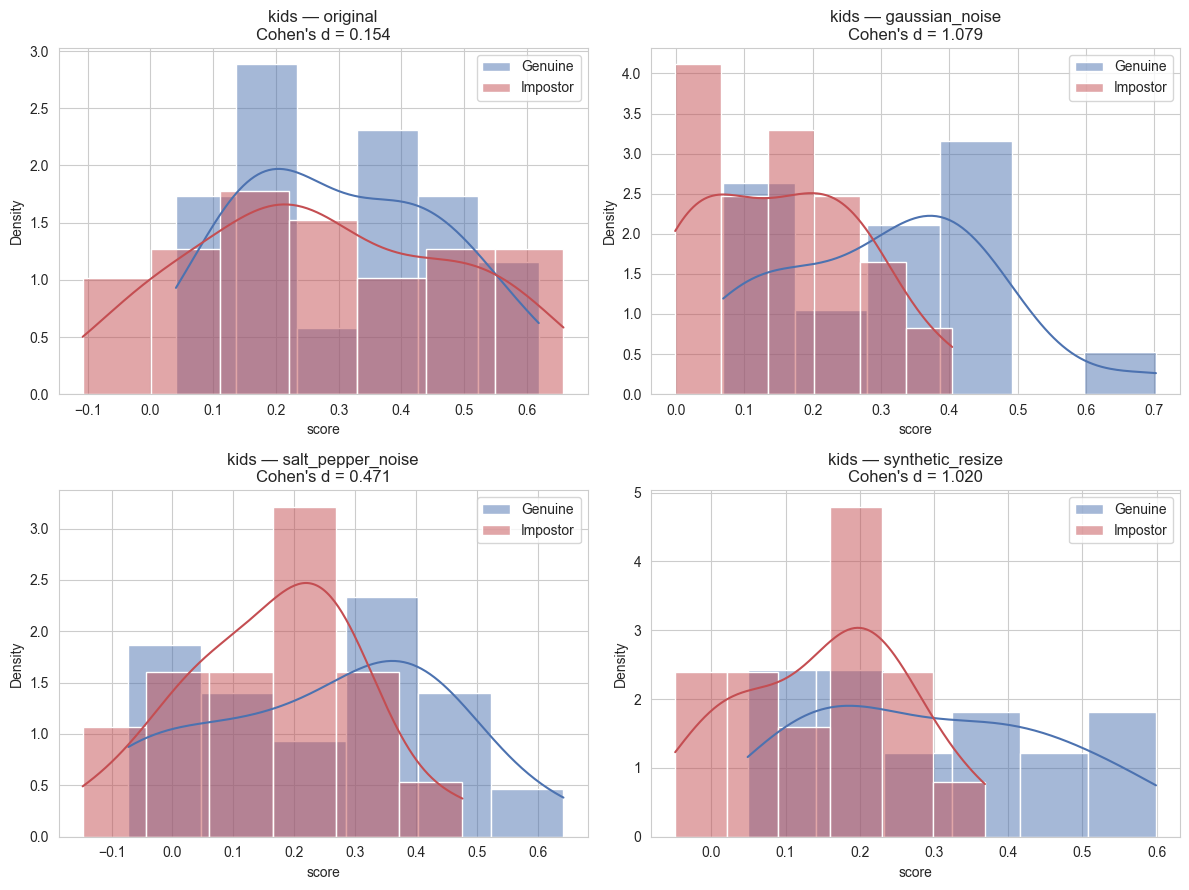

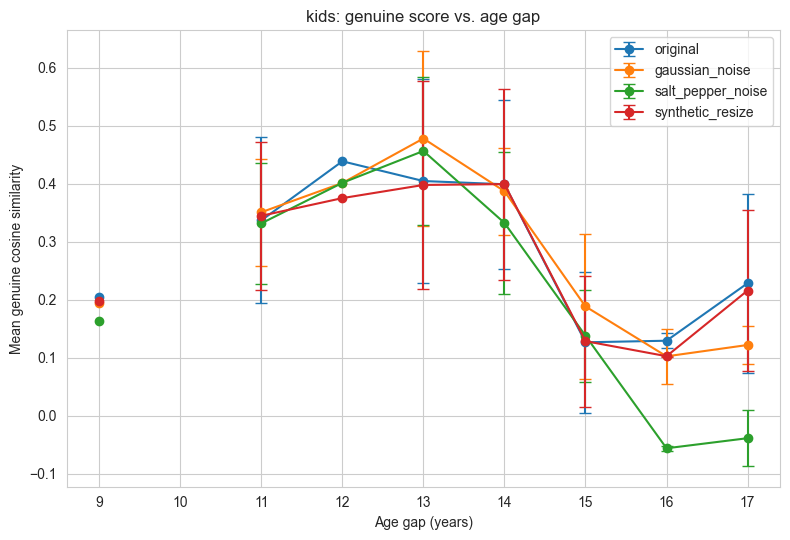

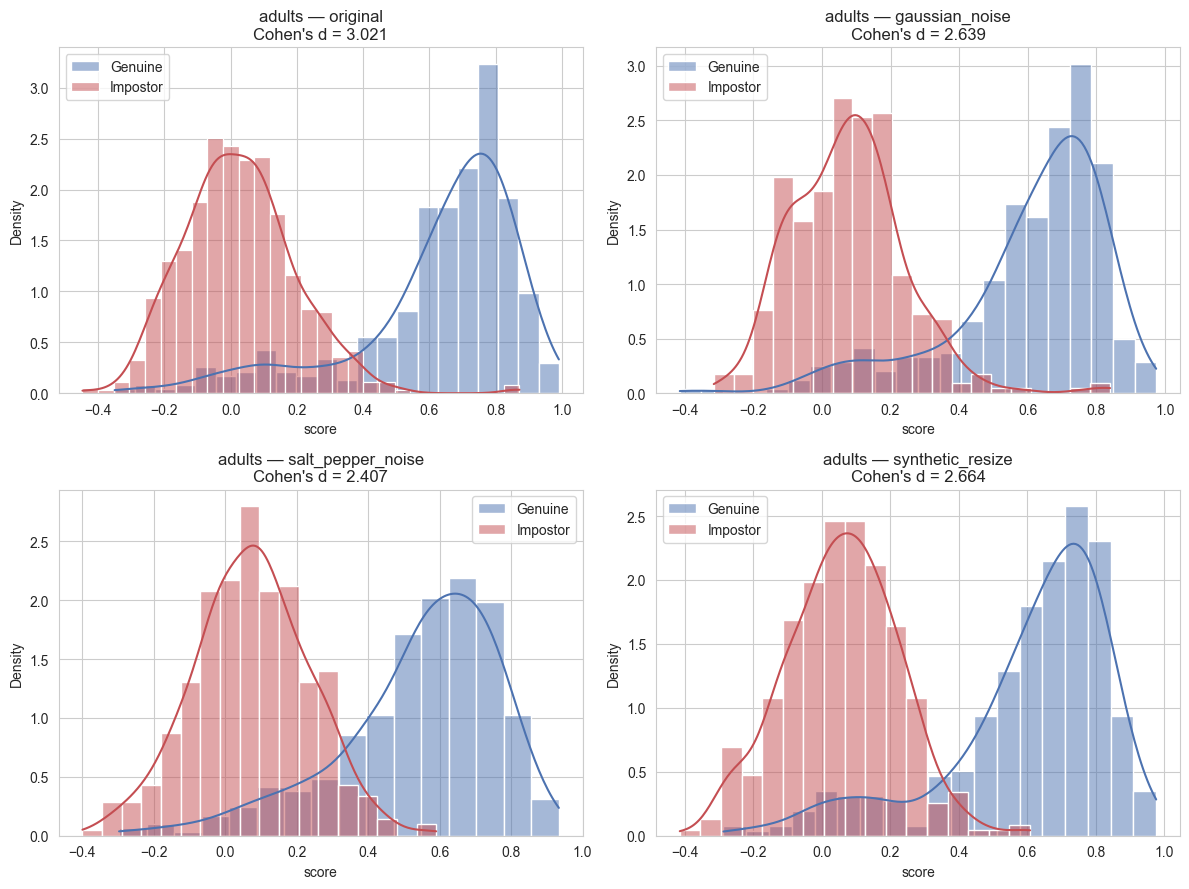

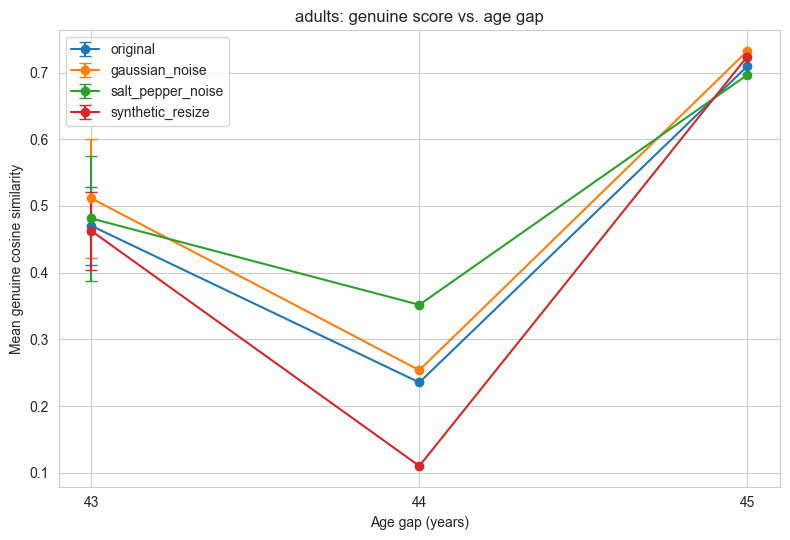

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def cohens_d(genuine, impostor):
    """Compute Cohen's d between genuine and impostor scores."""
    genuine = np.asarray(genuine.dropna())
    impostor = np.asarray(impostor.dropna())

    n_g = len(genuine)
    n_i = len(impostor)

    mean_g = genuine.mean()
    mean_i = impostor.mean()

    # Pooled standard deviation
    pooled_std = np.sqrt(
        ((n_g - 1) * genuine.var(ddof=1) +
         (n_i - 1) * impostor.var(ddof=1))
        / (n_g + n_i - 2)
    )

    if pooled_std == 0:
        return np.nan

    return (mean_g - mean_i) / pooled_std


for category in CATEGORIES:
    genuine_df, impostor_df, eer_df = all_results[category]
    results_dir = os.path.join(DATASET_ROOT, category, "results")

    
    # Distributions + Cohen's d
    
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))

    d_scores = {}

    for ax, version_name in zip(axes.ravel(), VERSIONS.keys()):
        g = genuine_df[
            genuine_df["version"] == version_name
        ]["score"].dropna()

        i = impostor_df[
            impostor_df["version"] == version_name
        ]["score"].dropna()

        # Cohen's d
        d = cohens_d(g, i)
        d_scores[version_name] = d

        # Plot distributions
        sns.histplot(
            g,
            color="#4C72B0",
            label="Genuine",
            stat="density",
            kde=True,
            ax=ax,
            alpha=0.5
        )

        sns.histplot(
            i,
            color="#C44E52",
            label="Impostor",
            stat="density",
            kde=True,
            ax=ax,
            alpha=0.5
        )

        ax.set_title(
            f"{category} — {version_name}\n"
            f"Cohen's d = {d:.3f}"
        )

        ax.legend()

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            results_dir,
            "genuine_vs_impostor_distributions.png"
        ),
        dpi=150
    )

    plt.show()

    # Save d-scores
    d_score_df = pd.DataFrame(
        list(d_scores.items()),
        columns=["version", "cohens_d"]
    )

    d_score_df.to_csv(
        os.path.join(results_dir, "d_scores.csv"),
        index=False
    )

    
    # Score vs age gap
    
    bins = [
        5, 6, 7, 8, 9, 10,
        11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 30,
        40, 41, 42, 43, 44, 45, 46, 47, 48, 49,
        50, 60, 70, 80, 90, 100, float("inf")
    ]

    labels = [
        "5", "6", "7", "8", "9", "10",
        "11", "12", "13", "14", "15", "16",
        "17", "18", "19",
        "20-29", "30-39",
        "40", "41", "42", "43", "44", "45",
        "46", "47", "48", "",
        "50-59", "60-69",
        "70-79", "80-89", "90-99", "100+"
    ]

    genuine_df["age_gap_bin"] = pd.cut(
        genuine_df["age_gap"],
        bins=bins,
        labels=labels,
        right=False,
        include_lowest=True
    )

    plt.figure(figsize=(8, 5.5))

    for version_name in VERSIONS:
        sub = genuine_df[
            genuine_df["version"] == version_name
        ]

        grouped = sub.groupby(
            "age_gap_bin",
            observed=False
        )["score"].agg(["mean", "std"])

        plt.errorbar(
            grouped.index.astype(str),
            grouped["mean"],
            yerr=grouped["std"],
            marker="o",
            capsize=4,
            label=version_name
        )

    plt.title(f"{category}: genuine score vs. age gap")
    plt.xlabel("Age gap (years)")
    plt.ylabel("Mean genuine cosine similarity")
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            results_dir,
            "score_vs_age_gap.png"
        ),
        dpi=150
    )

    plt.show()

    genuine_df.to_csv(
        os.path.join(
            results_dir,
            "genuine_scores.csv"
        ),
        index=False
    )


In [7]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

sns.set_style("whitegrid")

DATASET_ROOT = "./dataset_v2"
CATEGORIES = ["kids", "adults"]

genuine = {}
impostor = {}
eer = {}

for category in CATEGORIES:
    results_dir = os.path.join(DATASET_ROOT, category, "results")
    genuine[category] = pd.read_csv(os.path.join(results_dir, "genuine_scores.csv"))
    impostor[category] = pd.read_csv(os.path.join(results_dir, "impostor_scores.csv"))
    eer[category] = pd.read_csv(os.path.join(results_dir, "eer_summary.csv"))

VERSIONS = ["original", "gaussian_noise", "salt_pepper_noise", "synthetic_resize"]
COLORS = {"kids": "#8172B2", "adults": "#55A868"}

for c in CATEGORIES:
    print(c, "genuine:", len(genuine[c]), " impostor:", len(impostor[c]))


kids genuine: 72  impostor: 90
adults genuine: 1533  impostor: 1916


## 1. Genuine-score distributions: Kids vs Adults, per condition

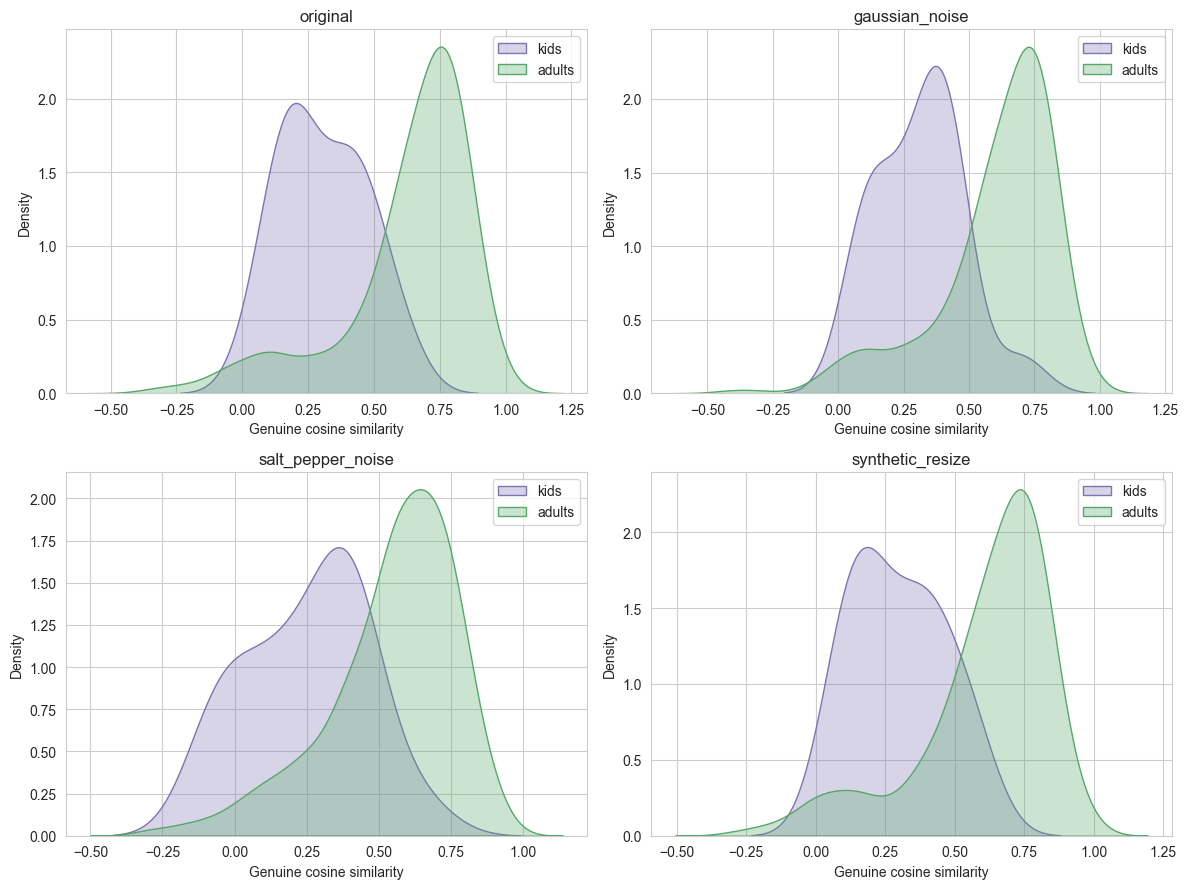

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, version_name in zip(axes.ravel(), VERSIONS):
    for category in CATEGORIES:
        scores = genuine[category][genuine[category]["version"] == version_name]["score"]
        sns.kdeplot(scores, ax=ax, label=category, color=COLORS[category], fill=True, alpha=0.3)
    ax.set_title(version_name)
    ax.set_xlabel("Genuine cosine similarity")
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(DATASET_ROOT, "compare_genuine_distributions.png"), dpi=150)
plt.show()


## 2. EER comparison — Kids vs Adults, per condition

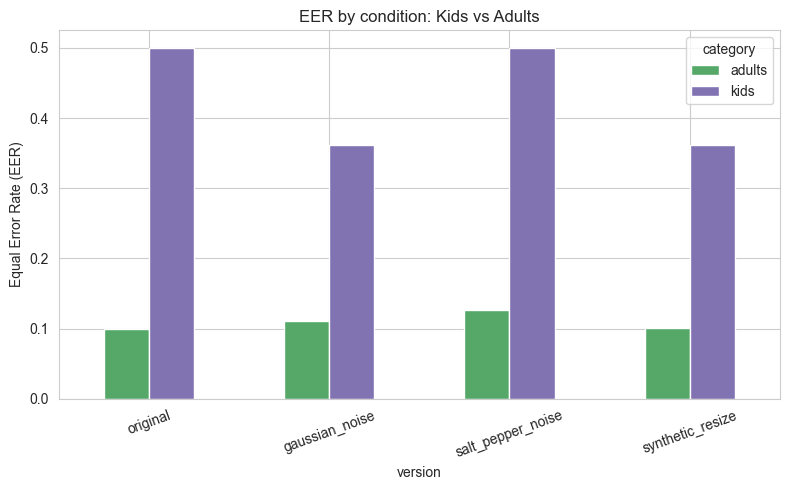

category,adults,kids
version,,
original,0.098701,0.500000
gaussian_noise,0.110823,0.361111
salt_pepper_noise,0.126818,0.500000
synthetic_resize,0.101299,0.361111


In [9]:
eer_all = pd.concat([eer[c] for c in CATEGORIES], ignore_index=True)
pivot_eer = eer_all.pivot(index="version", columns="category", values="EER").reindex(VERSIONS)

pivot_eer.plot(kind="bar", figsize=(8, 5), color=[COLORS[c] for c in pivot_eer.columns])
plt.ylabel("Equal Error Rate (EER)")
plt.title("EER by condition: Kids vs Adults")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(DATASET_ROOT, "compare_eer.png"), dpi=150)
plt.show()

pivot_eer


## 3. Score vs. age gap — Kids vs Adults, overlaid (original condition)

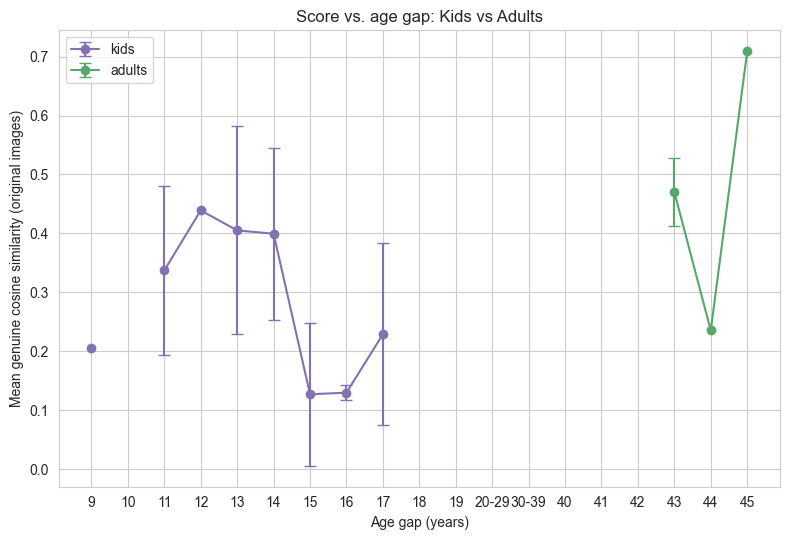

In [10]:
# bins = [5, 8, 11, 14, 17, 20, 30, 40, 50, 60, 70, 80, 90, 100, float("inf")]
# labels = [
#     "5-7", "8-10", "11-13", "14-16", "17-19",
#     "20-29", "30-39", "40-49", "50-59", "60-69",
#     "70-79", "80-89", "90-99", "100+"
# ]

bins = [5,6,7,8,9,10, 11,12,13, 14,15,16, 17,18,19, 20, 30, 40,41,42,43,44,45,46,47,48,49, 50, 60, 70, 80, 90, 100, float("inf")]
labels = [
    "5","6","7","8", "9","10", "11","12","13","14","15", "16", "17","18","19",
    "20-29", "30-39", "40","41","42","43","44","45","46","47","48","", "50-59", "60-69",
    "70-79", "80-89", "90-99", "100+"
    ]




plt.figure(figsize=(8, 5.5))

for category in CATEGORIES:
    df = genuine[category]
    df = df[df["version"] == "original"].copy()

    df["age_gap_bin"] = pd.cut(
        df["age_gap"],
        bins=bins,
        labels=labels,
        right=False,
        include_lowest=True
    )

    grouped = df.groupby(
        "age_gap_bin", observed=False
    )["score"].agg(["mean", "std"])

    plt.errorbar(
        grouped.index.astype(str),
        grouped["mean"],
        yerr=grouped["std"],
        marker="o",
        capsize=4,
        label=category,
        color=COLORS[category]
    )

plt.xlabel("Age gap (years)")
plt.ylabel("Mean genuine cosine similarity (original images)")
plt.title("Score vs. age gap: Kids vs Adults")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(DATASET_ROOT, "compare_score_vs_age_gap.png"),
    dpi=150
)

plt.show()


## 4. Is the Kids-vs-Adults difference statistically significant?

A quick **Mann-Whitney U test** (non-parametric, doesn't assume normality) on the genuine
score distributions per condition — useful to state in your report whether the observed gap
between categories is likely real or just sampling noise.


In [11]:
sig_rows = []
for version_name in VERSIONS:
    kids_scores = genuine["kids"][genuine["kids"]["version"] == version_name]["score"]
    adults_scores = genuine["adults"][genuine["adults"]["version"] == version_name]["score"]
    if len(kids_scores) < 3 or len(adults_scores) < 3:
        continue
    stat, p = mannwhitneyu(kids_scores, adults_scores, alternative="two-sided")
    sig_rows.append({
        "version": version_name,
        "kids_mean": kids_scores.mean(), "adults_mean": adults_scores.mean(),
        "U_stat": stat, "p_value": p, "significant_at_0.05": p < 0.05,
    })

sig_df = pd.DataFrame(sig_rows)
sig_df.to_csv(os.path.join(DATASET_ROOT, "kids_vs_adults_significance.csv"), index=False)
sig_df


,version,kids_mean,adults_mean,U_stat,p_value,significant_at_0.05
0,original,0.305938,0.628730,919.0,1.364616e-07,True
1,gaussian_noise,0.310462,0.603823,997.0,3.449764e-07,True
2,salt_pepper_noise,0.248587,0.543357,1064.0,7.843174e-07,True
3,synthetic_resize,0.297297,0.605905,964.0,2.257413e-07,True


## 5. Summary table: everything in one place

In [12]:
summary = pivot_eer.copy()
summary.columns = [f"EER_{c}" for c in summary.columns]
summary = summary.merge(
    sig_df.set_index("version")[["kids_mean", "adults_mean", "p_value"]],
    left_index=True, right_index=True, how="left"
)
summary.to_csv(os.path.join(DATASET_ROOT, "final_comparison_summary.csv"))
summary


,EER_adults,EER_kids,kids_mean,adults_mean,p_value
version,,,,,
original,0.098701,0.500000,0.305938,0.628730,1.364616e-07
gaussian_noise,0.110823,0.361111,0.310462,0.603823,3.449764e-07
salt_pepper_noise,0.126818,0.500000,0.248587,0.543357,7.843174e-07
synthetic_resize,0.101299,0.361111,0.297297,0.605905,2.257413e-07
